
 Linear Kernel
Accuracy: 0.8476259689922481
Precision: 0.8507827788649707
Recall: 0.8429471643238002
F1 Score: 0.8468468468468469

 RBF Kernel
Accuracy: 0.8626453488372093
Precision: 0.8659491193737769
Recall: 0.8579738245273874
F1 Score: 0.8619430241051863

Confusion Matrix: 
[[1791  274]
 [ 293 1770]]


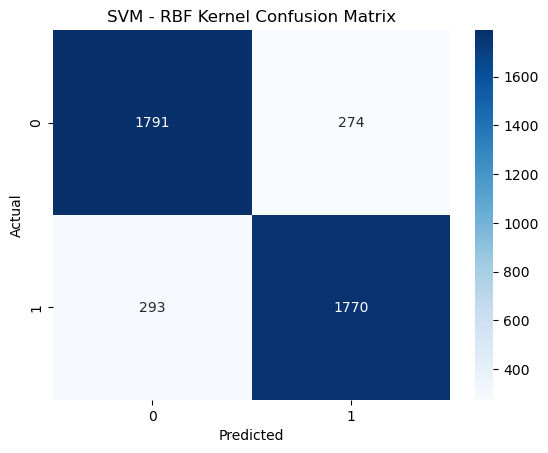

In [2]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
df = pd.read_csv(r"C:\Users\HP\Downloads\3,4,5,7.california_housing.csv")

df["HouseCategory"] = (df["MedHouseVal"] > df["MedHouseVal"].median()).astype(int)

X = df.drop(["MedHouseVal", "HouseCategory"], axis=1)
y = df["HouseCategory"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

linear = SVC(kernel="linear")
linear.fit(X_train, y_train)
linear_pred = linear.predict(X_test)

rbf = SVC(kernel="rbf")
rbf.fit(X_train, y_train)
rbf_pred = rbf.predict(X_test)

for name, pred in [("Linear Kernel", linear_pred),
                   ("RBF Kernel", rbf_pred)]:

    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred))
    print("Recall:", recall_score(y_test, pred))
    print("F1 Score:", f1_score(y_test, pred))

cm = confusion_matrix(y_test, rbf_pred)
print("\nConfusion Matrix: ")
print(cm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM - RBF Kernel Confusion Matrix")
plt.show()